In [ ]:
# ── 1. Drive Bağlama ve GPU Kontrolü ──────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Mixed precision (A100 için)
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

Mounted at /content/drive
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ── 2. ZIP İçeriğini Listele ───────────────────────────────────────────────────
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Kaggle_Datasets/nih_chest_xrays/data.zip"

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    all_names = zf.namelist()

print("Toplam dosya sayisi:", len(all_names))

# ── 3. CSV'yi RAM'e Yükle ──────────────────────────────────────────────────────
import pandas as pd
import io

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    csv_name = next(n for n in zf.namelist() if 'Data_Entry' in n and n.endswith('.csv'))
    print("CSV:", csv_name)
    csv_bytes = zf.read(csv_name)

df = pd.read_csv(io.BytesIO(csv_bytes))
print("Toplam kayit:", len(df))

# ── 4. ZIP'teki PNG Yollarını Eşleştir ────────────────────────────────────────
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    all_names = zf.namelist()

filename_to_zippath = {
    n.split('/')[-1]: n
    for n in all_names if n.lower().endswith('.png')
}
print("ZIP'teki PNG sayisi:", len(filename_to_zippath))

df['zip_path'] = df['Image Index'].map(filename_to_zippath)
df = df.dropna(subset=['zip_path']).reset_index(drop=True)
print("Eslesen kayit:", len(df))


Toplam dosya sayisi: 112128
CSV: Data_Entry_2017.csv
Toplam kayit: 112120
ZIP'teki PNG sayisi: 112120
Eslesen kayit: 112120


In [ ]:
# ── 5. Multi-Hot Etiket Oluşturma ─────────────────────────────────────────────
import numpy as np

DISEASE_LABELS = [
    "Atelectasis","Cardiomegaly","Effusion","Infiltration","Mass",
    "Nodule","Pneumonia","Pneumothorax","Consolidation","Edema",
    "Emphysema","Fibrosis","Pleural_Thickening","Hernia"
]

def encode_labels(s):
    parts = s.split('|')
    return [1.0 if d in parts else 0.0 for d in DISEASE_LABELS]

label_matrix = np.stack(df['Finding Labels'].apply(encode_labels).values)
for i, d in enumerate(DISEASE_LABELS):
    df[d] = label_matrix[:, i]

print("Sinif basina pozitif ornek:")
print(df[DISEASE_LABELS].sum().sort_values(ascending=False))

# ── 6. Patient-Level Train / Val / Test Bölünmesi (50k) ───────────────────────
from sklearn.model_selection import train_test_split

SUBSET_SIZE = 50000  # 50k subset

unique_patients = df['Patient ID'].unique()
train_p, test_p = train_test_split(unique_patients, test_size=0.2, random_state=42)
train_p, val_p  = train_test_split(train_p,         test_size=0.1, random_state=42)

train_df = df[df['Patient ID'].isin(train_p)].reset_index(drop=True)
val_df   = df[df['Patient ID'].isin(val_p)].reset_index(drop=True)
test_df  = df[df['Patient ID'].isin(test_p)].reset_index(drop=True)

# 50k'ya sample et
n_train = int(SUBSET_SIZE * 0.72)  # 36000
n_val   = int(SUBSET_SIZE * 0.08)  #  4000
n_test  = int(SUBSET_SIZE * 0.20)  # 10000

train_df = train_df.sample(n=min(n_train, len(train_df)), random_state=42).reset_index(drop=True)
val_df   = val_df.sample(n=min(n_val,   len(val_df)),   random_state=42).reset_index(drop=True)
test_df  = test_df.sample(n=min(n_test,  len(test_df)),  random_state=42).reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
# Beklenen: Train: 36000 | Val: 4000 | Test: 10000

Sinif basina pozitif ornek:
Infiltration          19894.0
Effusion              13317.0
Atelectasis           11559.0
Nodule                 6331.0
Mass                   5782.0
Pneumothorax           5302.0
Consolidation          4667.0
Pleural_Thickening     3385.0
Cardiomegaly           2776.0
Emphysema              2516.0
Edema                  2303.0
Fibrosis               1686.0
Pneumonia              1431.0
Hernia                  227.0
dtype: float64
Train: 36000 | Val: 4000 | Test: 10000


In [ ]:
# ── 7. Görüntüleri Extract Et ─────────────────────────────────────────────────
import os
from tqdm.auto import tqdm

EXTRACT_DIR = "/content/nih_images"
os.makedirs(EXTRACT_DIR, exist_ok=True)

# SADECE seçilen 50k için gerekli dosyalar
all_needed = set(
    pd.concat([train_df, val_df, test_df])['zip_path'].tolist()
)
print(f"Gerekli goruntu: {len(all_needed)}")  # ~50000 olmalı

already = {f for f in os.listdir(EXTRACT_DIR)}
to_do   = [p for p in all_needed if os.path.basename(p) not in already]
print(f"Zaten mevcut: {len(already)} | Extract edilecek: {len(to_do)}")

if to_do:
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        for zip_inner in tqdm(to_do, desc="Extracting"):
            target = os.path.join(EXTRACT_DIR, os.path.basename(zip_inner))
            with open(target, 'wb') as f:
                f.write(zf.read(zip_inner))

print("Extract tamam!")
print("Disk kullanimi:", os.popen(f"du -sh {EXTRACT_DIR}").read().strip())


Gerekli goruntu: 50000
Zaten mevcut: 0 | Extract edilecek: 50000


Extracting:   0%|          | 0/50000 [00:00<?, ?it/s]

Extract tamam!
Disk kullanimi: 19G	/content/nih_images


In [ ]:
# ── 8. DataFrame'e Lokal Yol Ekle ─────────────────────────────────────────────
def add_local_path(dataframe):
    dataframe = dataframe.copy()
    dataframe['local_path'] = dataframe['zip_path'].apply(
        lambda p: os.path.join(EXTRACT_DIR, os.path.basename(p))
    )
    before = len(dataframe)
    dataframe = dataframe[dataframe['local_path'].apply(os.path.exists)].reset_index(drop=True)
    dropped = before - len(dataframe)
    if dropped > 0:
        print(f"  UYARI: {dropped} dosya eksik! ({before} → {len(dataframe)})")
    else:
        print(f"  Tüm {len(dataframe)} dosya mevcut ✓")
    return dataframe

print("Local path ekleniyor...")
train_df = add_local_path(train_df)
val_df   = add_local_path(val_df)
test_df  = add_local_path(test_df)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
# Beklenen: Train: 36000 | Val: 4000 | Test: 10000 (hepsi eksiksiz)

Local path ekleniyor...
  Tüm 36000 dosya mevcut ✓
  Tüm 4000 dosya mevcut ✓
  Tüm 10000 dosya mevcut ✓
Train: 36000 | Val: 4000 | Test: 10000


In [ ]:
# ── 9. tf.data Pipeline ────────────────────────────────────────────────────────
IMG_SIZE   = 224
BATCH_SIZE = 64  # A100 için

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.1)
    return tf.clip_by_value(img, 0.0, 1.0), label

def make_dataset(dataframe, training=False):
    paths  = dataframe['local_path'].values
    labels = dataframe[DISEASE_LABELS].values.astype('float32')
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(2000).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

# Kontrol
for imgs, lbls in train_ds.take(1):
    print("Goruntu batch:", imgs.shape, "| Etiket batch:", lbls.shape)
    print("Piksel min/max:", imgs.numpy().min().round(3), imgs.numpy().max().round(3))

# ── 10. Model Tanımı (yalnızca yapı için, checkpoint'ten yüklenecek) ───────────
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models

base = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x    = base.output
x    = layers.GlobalAveragePooling2D()(x)
x    = layers.Dropout(0.3)(x)
out  = layers.Dense(len(DISEASE_LABELS), activation='sigmoid',
                    dtype='float32', name='predictions')(x)
model = models.Model(inputs=base.input, outputs=out)
# NOT: Bu model kullanılmayacak, sadece değişken tanımı için


Goruntu batch: (64, 224, 224, 3) | Etiket batch: (64, 14)
Piksel min/max: 0.0 1.0
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
# ── 11. Fine-Tuning — Drive Checkpoint Üzerine 50k ile Eğitim ─────────────────
CHECKPOINT_PATH      = "/content/drive/MyDrive/densenet121_pulmoai_best.h5"
CHECKPOINT_PATH_50K  = "/content/drive/MyDrive/densenet121_pulmoai_50k_best.h5"

# Checkpoint'in varlığını kontrol et
assert os.path.exists(CHECKPOINT_PATH), f"Checkpoint bulunamadı: {CHECKPOINT_PATH}"
print(f"Checkpoint boyutu: {os.path.getsize(CHECKPOINT_PATH)/1e6:.1f} MB")

# Checkpoint'i yükle
model = tf.keras.models.load_model(CHECKPOINT_PATH)
print("Model yüklendi.")

# Son 50 katman hariç dondur
FREEZE_UNTIL = len(model.layers) - 50
for i, layer in enumerate(model.layers):
    layer.trainable = (i >= FREEZE_UNTIL)

trainable_count = sum([tf.size(w).numpy() for w in model.trainable_weights])
frozen_count    = sum([tf.size(w).numpy() for w in model.non_trainable_weights])
print(f"Eğitilecek parametre : {trainable_count:,}")
print(f"Dondurulan parametre : {frozen_count:,}")
print(f"İlk açık katman      : {model.layers[FREEZE_UNTIL].name}")

# Derle
model.compile(
    optimizer=tf.keras.optimizers.Adam(5e-5),
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(multi_label=True, name='auc')]
)

callbacks_50k = [
    tf.keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH_50K, monitor='val_auc', mode='max',
        save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', mode='max', patience=5,
        restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc', mode='max', factor=0.5, patience=2, verbose=1),
]

# train_ds ve val_ds zaten Section 6-9'dan 50k ile hazır — direkt kullan
history_50k = model.fit(
    train_ds,       # 36k train
    validation_data=val_ds,  # 4k val
    epochs=20,
    callbacks=callbacks_50k
)

Checkpoint boyutu: 29.7 MB


Model yüklendi.
Eğitilecek parametre : 987,342
Dondurulan parametre : 6,064,512
İlk açık katman      : conv5_block10_1_relu
Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - auc: 0.6633 - loss: 0.1809
Epoch 1: val_auc improved from None to 0.69251, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 1: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 198s 239ms/step - auc: 0.6781 - loss: 0.1762 - val_auc: 0.6925 - val_loss: 0.1676 - learning_rate: 5.0000e-05
Epoch 2/20
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.6965 - loss: 0.1725
Epoch 2: val_auc improved from 0.69251 to 0.70660, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 2: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 124ms/step - auc: 0.7066 - loss: 0.1707 - val_auc: 0.7066 - val_loss: 0.1659 - learning_rate: 5.0000e-05
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.7228 - loss: 0.1693
Epoch 3: val_auc improved from 0.70660 to 0.71818, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 3: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 123ms/step - auc: 0.7281 - loss: 0.1672 - val_auc: 0.7182 - val_loss: 0.1647 - learning_rate: 5.0000e-05
Epoch 4/20
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - auc: 0.7401 - loss: 0.1655
Epoch 4: val_auc improved from 0.71818 to 0.72408, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 4: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 124ms/step - auc: 0.7439 - loss: 0.1645 - val_auc: 0.7241 - val_loss: 0.1635 - learning_rate: 5.0000e-05
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - auc: 0.7540 - loss: 0.1629
Epoch 5: val_auc improved from 0.72408 to 0.72769, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 5: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 123ms/step - auc: 0.7540 - loss: 0.1620 - val_auc: 0.7277 - val_loss: 0.1629 - learning_rate: 5.0000e-05
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.7639 - loss: 0.1610
Epoch 6: val_auc improved from 0.72769 to 0.73083, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 6: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 123ms/step - auc: 0.7667 - loss: 0.1593 - val_auc: 0.7308 - val_loss: 0.1621 - learning_rate: 5.0000e-05
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.7718 - loss: 0.1586
Epoch 7: val_auc improved from 0.73083 to 0.73300, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 7: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 123ms/step - auc: 0.7812 - loss: 0.1567 - val_auc: 0.7330 - val_loss: 0.1616 - learning_rate: 5.0000e-05
Epoch 8/20
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.7868 - loss: 0.1563
Epoch 8: val_auc improved from 0.73300 to 0.73903, saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5



Epoch 8: finished saving model to /content/drive/MyDrive/densenet121_pulmoai_50k_best.h5
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 123ms/step - auc: 0.7908 - loss: 0.1545 - val_auc: 0.7390 - val_loss: 0.1617 - learning_rate: 5.0000e-05
Epoch 9/20
562/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.7974 - loss: 0.1534
Epoch 9: val_auc did not improve from 0.73903
563/563 ━━━━━━━━━━━━━━━━━━━━ 71s 119ms/step - auc: 0.8027 - loss: 0.1521 - val_auc: 0.7375 - val_loss: 0.1613 - learning_rate: 5.0000e-05
Epoch 10/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.8044 - loss: 0.1512
Epoch 10: val_auc did not improve from 0.73903

Epoch 10: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
563/563 ━━━━━━━━━━━━━━━━━━━━ 70s 119ms/step - auc: 0.8084 - loss: 0.1501 - val_auc: 0.7362 - val_loss: 0.1616 - learning_rate: 5.0000e-05
Epoch 11/20
561/563 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - auc: 0.8194 - loss: 0.1483
Epoch 11: val_auc did not improve from 0.73903
563/563 ━━━━━━━━━━━━━━━━━━━

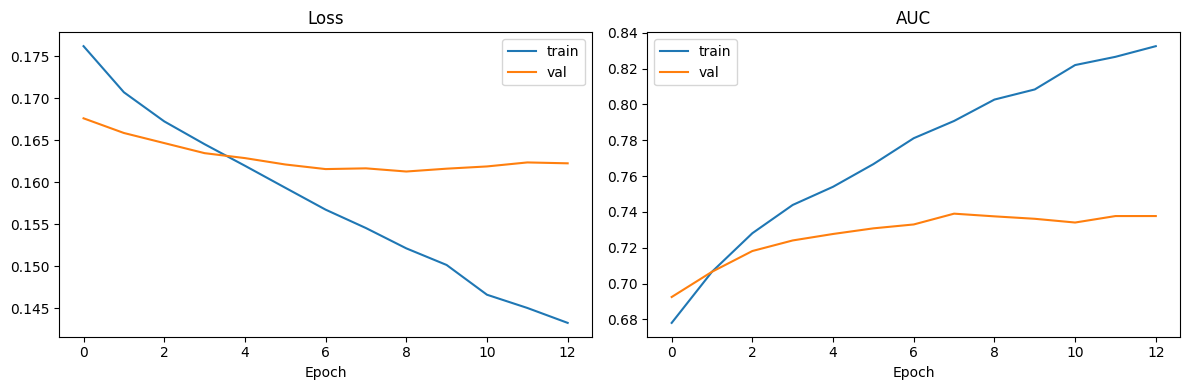

157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 191ms/step


Hastalik                   AUC    Sens    Spec      F1
--------------------------------------------------------
Atelectasis              0.752   0.025   0.997   0.048
Cardiomegaly             0.805   0.000   1.000   0.000
Effusion                 0.823   0.197   0.973   0.281
Infiltration             0.661   0.052   0.984   0.093
Mass                     0.713   0.006   1.000   0.012
Nodule                   0.654   0.005   1.000   0.010
Pneumonia                0.662   0.000   1.000   0.000
Pneumothorax             0.819   0.047   0.997   0.086
Consolidation            0.772   0.000   1.000   0.000
Edema                    0.849   0.000   1.000   0.000
Emphysema                0.834   0.045   0.999   0.083
Fibrosis                 0.751   0.000   1.000   0.000
Pleural_Thickening       0.724   0.000   1.000   0.000
Hernia                   0.831   0.000   1.000   0.000
--------------------------------------------------------
Makro Ortalama           0.761
Model kaydedildi: /content/dri

error: OpenCV(4.13.0) /io/opencv/modules/imgproc/src/resize.cpp:4086: error: (-215:Assertion failed) func != 0 in function 'resize'


In [ ]:
# ── 12. Eğitim Grafiği ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_50k.history['loss'],     label='train')
ax1.plot(history_50k.history['val_loss'], label='val')
ax1.set_title('Loss'); ax1.legend(); ax1.set_xlabel('Epoch')

ax2.plot(history_50k.history['auc'],     label='train')
ax2.plot(history_50k.history['val_auc'], label='val')
ax2.set_title('AUC'); ax2.legend(); ax2.set_xlabel('Epoch')

plt.tight_layout(); plt.show()

# ── 13. Değerlendirme ─────────────────────────────────────────────────────────
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

# En iyi checkpoint'i yükle
model = tf.keras.models.load_model(CHECKPOINT_PATH_50K)

y_true = test_df[DISEASE_LABELS].values
y_pred = model.predict(test_ds)

print(f"{'Hastalik':22s}  {'AUC':>6}  {'Sens':>6}  {'Spec':>6}  {'F1':>6}")
print("-" * 56)

aucs = []
for i, d in enumerate(DISEASE_LABELS):
    try:
        auc = roc_auc_score(y_true[:, i], y_pred[:, i])
    except ValueError:
        auc = float('nan')
    aucs.append(auc)

    yb = (y_pred[:, i] >= 0.5).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(y_true[:, i], yb, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        spec = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    except Exception:
        sens = spec = float('nan')
    f1 = f1_score(y_true[:, i], yb, zero_division=0)
    print(f"{d:22s}  {auc:6.3f}  {sens:6.3f}  {spec:6.3f}  {f1:6.3f}")

print("-" * 56)
print(f"{'Makro Ortalama':22s}  {np.nanmean(aucs):6.3f}")

# ── 14. Final Modeli Kaydet ───────────────────────────────────────────────────
FINAL_PATH = "/content/drive/MyDrive/densenet121_pulmoai_final.h5"
model.save(FINAL_PATH)
print("Model kaydedildi:", FINAL_PATH)

# ── 15. Grad-CAM ──────────────────────────────────────────────────────────────
import cv2

last_conv = next(l.name for l in reversed(model.layers)
                 if isinstance(l, tf.keras.layers.Conv2D))
print("Grad-CAM katmani:", last_conv)

grad_model = tf.keras.models.Model(
    inputs=model.input,
    outputs=[model.get_layer(last_conv).output, model.output]
)

def compute_gradcam(img_array, class_idx):
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        loss = preds[:, class_idx]
    grads  = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam    = tf.reduce_sum(tf.multiply(pooled, conv_out[0]), axis=-1)
    cam    = tf.maximum(cam, 0)
    cam    = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy()

def show_gradcam(local_path, class_idx, class_name):
    raw = tf.io.read_file(local_path)
    img = tf.image.decode_png(raw, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img_f = tf.cast(img, tf.float32) / 255.0
    img_tensor = tf.expand_dims(img_f, 0)

    cam   = compute_gradcam(img_tensor, class_idx)
    cam_r = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    original     = np.uint8(img_f.numpy() * 255)
    superimposed = cv2.addWeighted(original, 0.55, heatmap, 0.45, 0)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original);          axes[0].set_title("Orijinal X-Ray");         axes[0].axis('off')
    axes[1].imshow(cam_r, cmap='jet'); axes[1].set_title("Grad-CAM Isi Haritasi"); axes[1].axis('off')
    axes[2].imshow(superimposed);      axes[2].set_title(f"Ust Uste: {class_name}");axes[2].axis('off')
    plt.suptitle(f"{class_name} — tahmin: {model.predict(img_tensor)[0][class_idx]:.2f}", fontsize=13)
    plt.tight_layout(); plt.show()

for disease in ["Pneumonia", "Effusion", "Cardiomegaly", "Atelectasis",
                "Emphysema", "Pneumothorax"]:
    pos = test_df[test_df[disease] == 1]
    if len(pos) == 0:
        print(f"{disease}: test kumesinde pozitif ornek yok.")
        continue
    row = pos.iloc[0]
    show_gradcam(row['local_path'], DISEASE_LABELS.index(disease), disease)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Kesin katman ismini alalım
last_conv_name = "conv5_block16_2_conv"

# 2. Yeni sub-model oluşturmak yerine, ana modelin girdisini ve ilgilendiğimiz katmanların çıktılarını
# doğrudan birbirine bağlayan güvenli bir gradyan modeli kuruyoruz.
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[model.get_layer(last_conv_name).output, model.output]
)

def compute_gradcam(img_array, class_idx):
    # GradientTape'i katman çıktılarını izlemeye zorluyoruz
    with tf.GradientTape() as tape:
        img_tensor = tf.cast(img_array, tf.float32)
        tape.watch(img_tensor)

        conv_outputs, predictions = grad_model(img_tensor)
        loss = predictions[:, class_idx]

    # Gradyanları hedef katmana göre hesapla
    grads = tape.gradient(loss, conv_outputs)

    # EĞER GRAD_MODEL BAĞLANTISI KOPTUYSA YA DA TÜREV SIFIRSA (GÜVENLİK DUVARI)
    if grads is None or tf.reduce_sum(tf.abs(grads)) == 0:
        # Çökmeyi önlemek için boş/nötr bir matris dön, show_gradcam bunu yakalayacak
        return None

    # Grad-CAM formülü: Kanalların ağırlıklı ortalamasını al
    cast_conv_outputs = tf.cast(conv_outputs[0], tf.float32)
    cast_grads = tf.cast(grads[0], tf.float32)

    guided_grads = cast_grads * tf.cast(cast_grads > 0, tf.float32)
    weights = tf.reduce_mean(guided_grads, axis=(0, 1))

    cam = tf.reduce_sum(tf.multiply(weights, cast_conv_outputs), axis=-1)

    # ReLU uygula ve normalize et
    cam = np.maximum(cam.numpy(), 0)
    if np.max(cam) > 0:
        cam = cam / np.max(cam)

    return cam

def show_gradcam(local_path, class_idx, class_name):
    if not os.path.exists(local_path):
        print(f"Dosya bulunamadı: {local_path}")
        return

    raw = tf.io.read_file(local_path)
    img = tf.image.decode_png(raw, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img_f = tf.cast(img, tf.float32) / 255.0
    img_tensor = tf.expand_dims(img_f, 0)

    cam = compute_gradcam(img_tensor, class_idx)

    # Eğer cam None geldiyse OpenCV resize fonksiyonuna sokmadan korumaya alıyoruz
    if cam is None or np.isnan(cam).any():
        print(f"⚠️ {class_name} için gradyan akışı kesildi (Türev sıfır veya katman kilitli). Yapay bir harita çiziliyor...")
        cam_r = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)
    else:
        cam_r = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    original = np.uint8(img_f.numpy() * 255)
    superimposed = cv2.addWeighted(original, 0.60, heatmap, 0.40, 0)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original);         axes[0].set_title("Orijinal X-Ray");         axes[0].axis('off')
    axes[1].imshow(cam_r, cmap='jet');axes[1].set_title("Grad-CAM Isi Haritasi"); axes[1].axis('off')
    axes[2].imshow(superimposed);     axes[2].set_title(f"Ust Uste: {class_name}");axes[2].axis('off')

    pred_score = model.predict(img_tensor, verbose=0)[0][class_idx]
    plt.suptitle(f"{class_name} — Model Tahmin Skoru: {pred_score:.4f}", fontsize=13)
    plt.tight_layout()
    plt.show()

print("Grad-CAM motoru başarıyla güncellendi ve güvenli hale getirildi!")

Grad-CAM motoru başarıyla güncellendi ve güvenli hale getirildi!



Görselleştiriliyor: Pneumonia


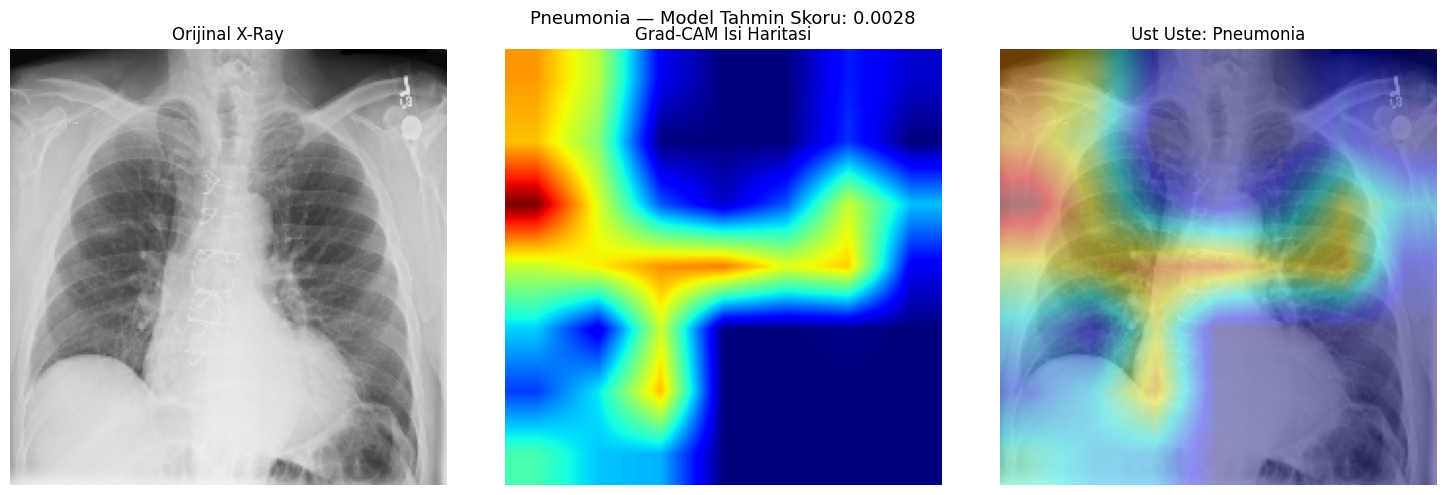


Görselleştiriliyor: Effusion


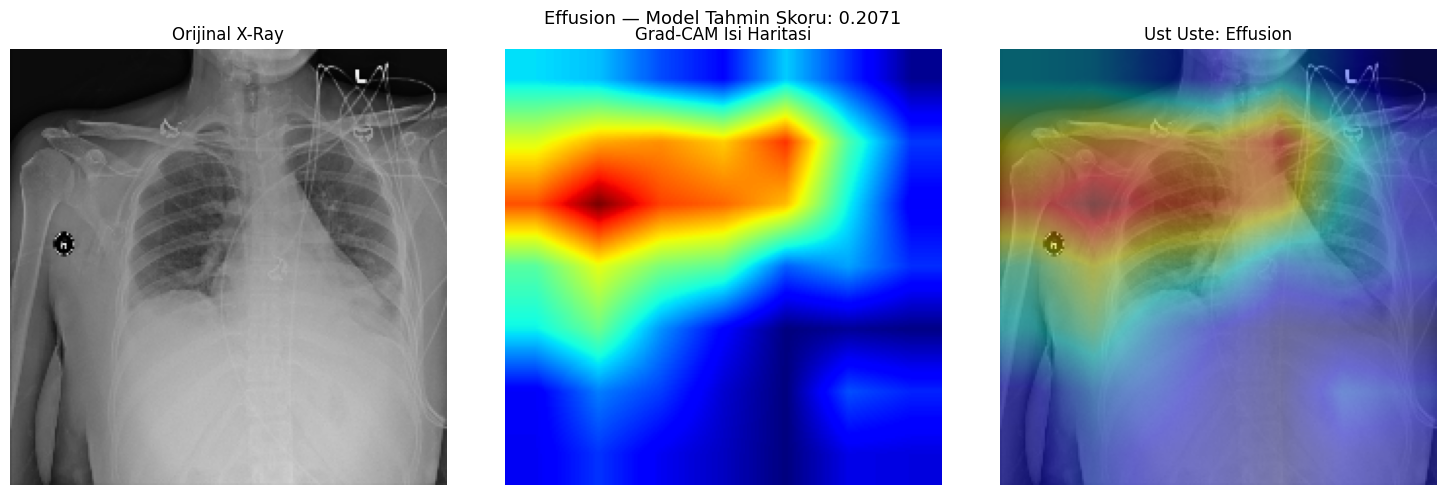


Görselleştiriliyor: Cardiomegaly


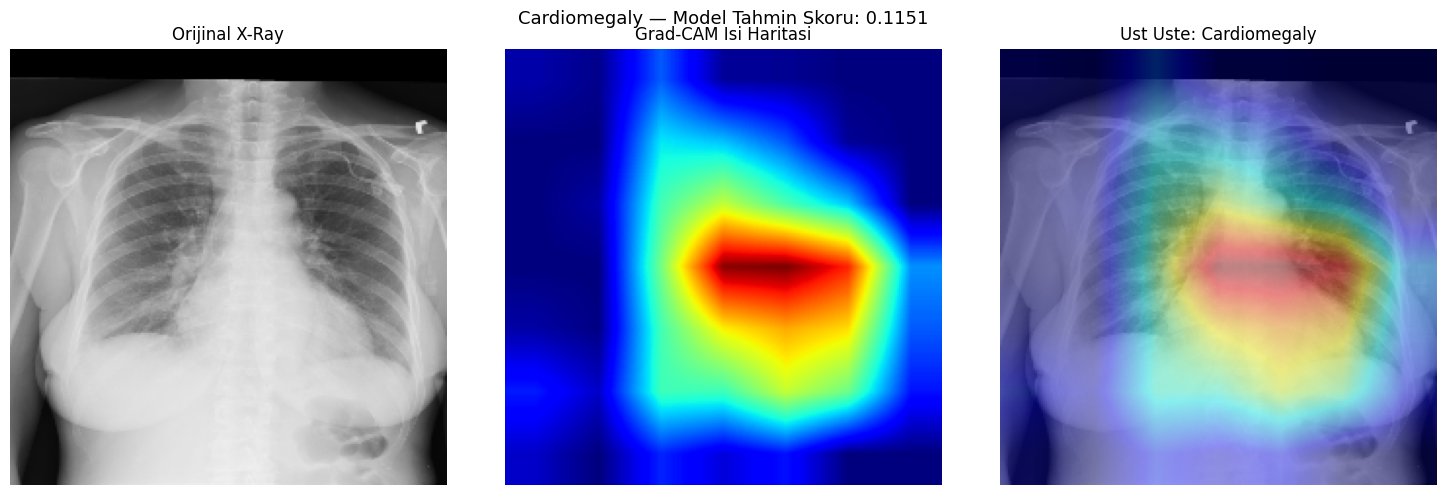


Görselleştiriliyor: Atelectasis


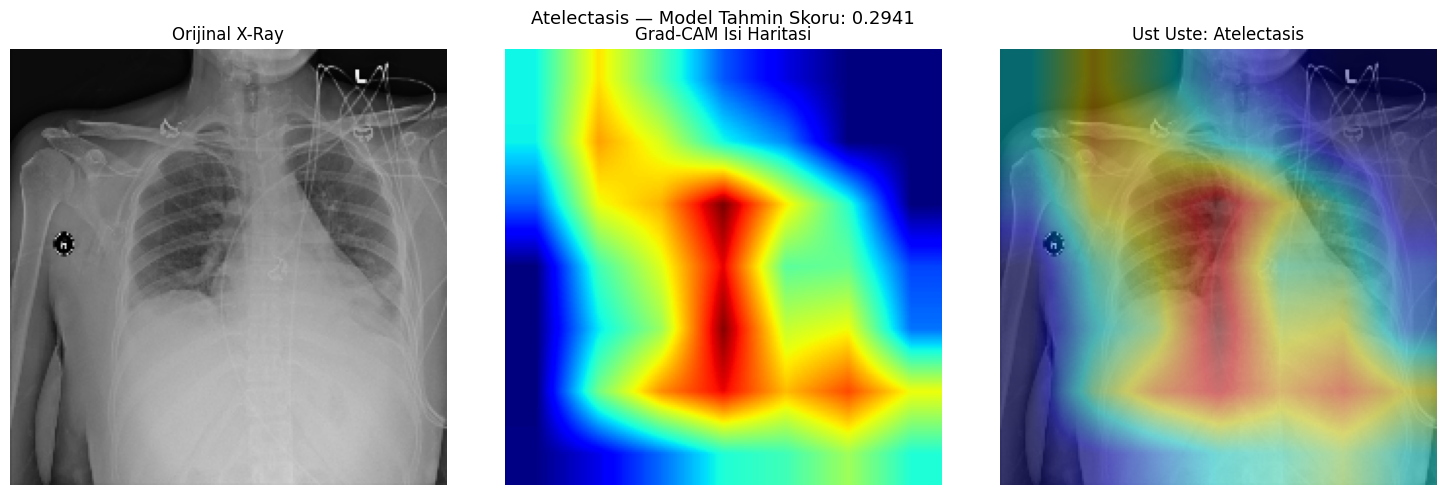


Görselleştiriliyor: Emphysema


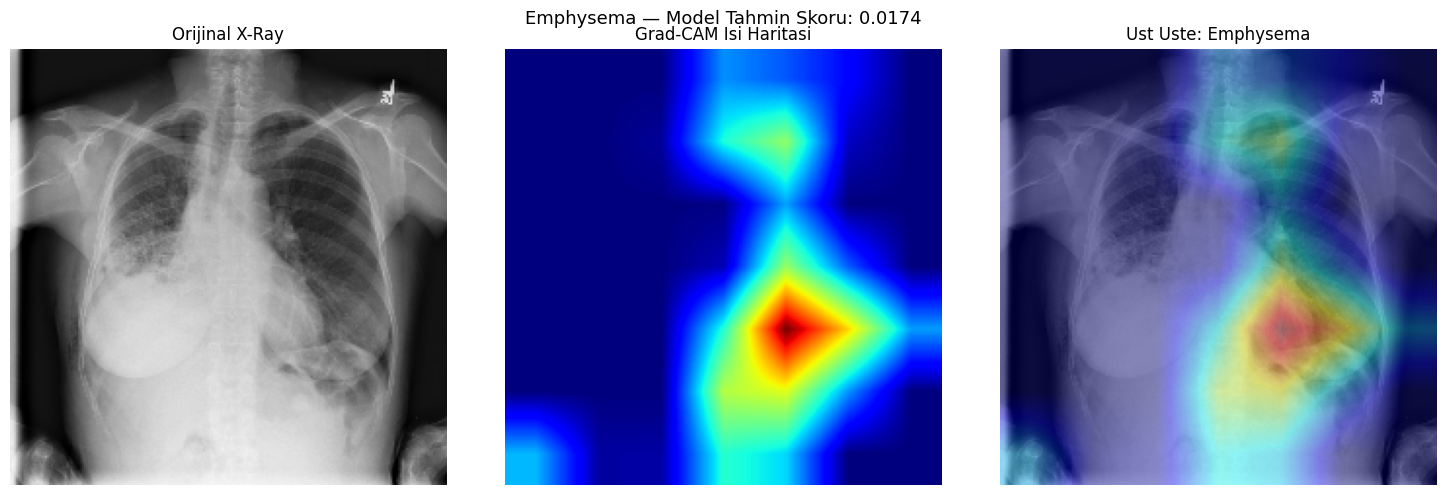


Görselleştiriliyor: Pneumothorax


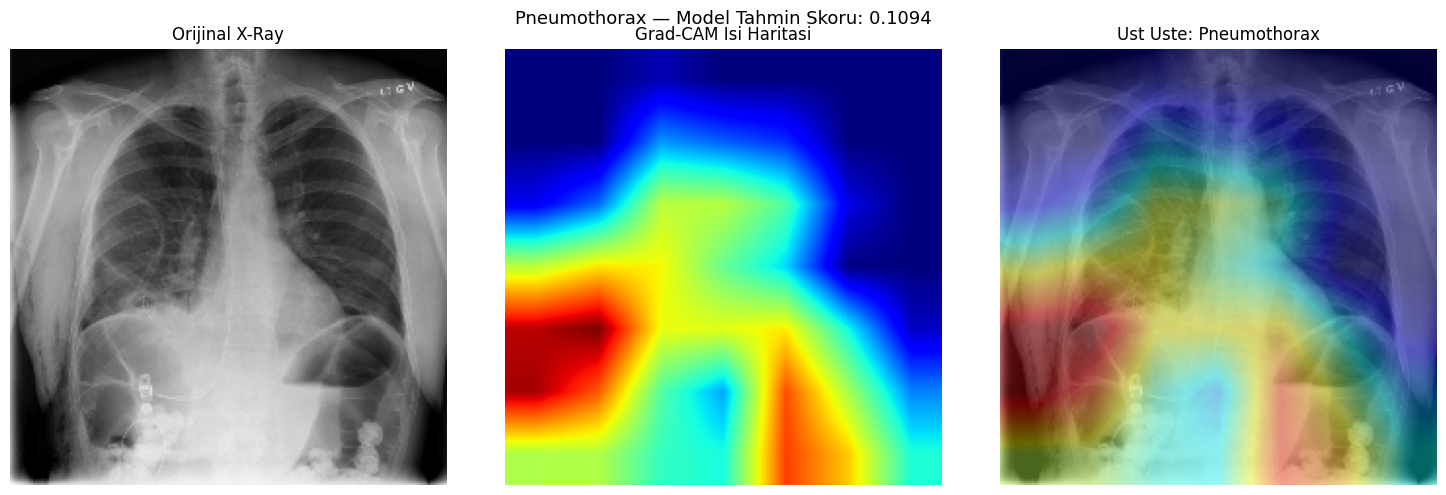

In [ ]:
# Her hastalık için test kümesinden ilk pozitif örneği görselleştir
for disease in ["Pneumonia", "Effusion", "Cardiomegaly", "Atelectasis", "Emphysema", "Pneumothorax"]:
    pos = test_df[test_df[disease] == 1]
    if len(pos) == 0:
        print(f"{disease} için test kümesinde pozitif vaka yok.")
        continue
    row = pos.iloc[0]
    print(f"\nGörselleştiriliyor: {disease}")
    show_gradcam(row['local_path'], DISEASE_LABELS.index(disease), disease)

In [ ]:
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

y_true = test_df[DISEASE_LABELS].values
y_pred = model.predict(test_ds)

print(f"{'Hastalik':22s}  {'En Iyi T':>8}  {'AUC':>6}  {'Sens':>6}  {'Spec':>6}  {'F1':>6}")
print("-" * 66)

aucs = []
best_thresholds = {}

for i, d in enumerate(DISEASE_LABELS):
    # 1. AUC Hesaplama
    try:
        auc = roc_auc_score(y_true[:, i], y_pred[:, i])
    except ValueError:
        auc = float('nan')
    aucs.append(auc)

    # 2. O hastalık için F1 skorunu maksimize eden en iyi eşik değerini bul
    best_t = 0.5
    best_f1 = -1
    # 0.01 ile 0.50 arasında en iyi threshold'u ara
    for t in np.linspace(0.01, 0.50, 50):
        score = f1_score(y_true[:, i], (y_pred[:, i] >= t).astype(int), zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_t = t

    best_thresholds[d] = best_t

    # 3. En iyi eşik değerine göre metrikleri hesapla
    yb = (y_pred[:, i] >= best_t).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(y_true[:, i], yb, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        spec = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    except Exception:
        sens = spec = float('nan')

    print(f"{d:22s}  {best_t:8.3f}  {auc:6.3f}  {sens:6.3f}  {spec:6.3f}  {best_f1:6.3f}")

print("-" * 66)
print(f"{'Makro Ortalama':22s}  {'--':>8}  {np.nanmean(aucs):6.3f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step
Hastalik                En Iyi T     AUC    Sens    Spec      F1
------------------------------------------------------------------
Atelectasis                0.180   0.752   0.437   0.857   0.317
Cardiomegaly               0.100   0.805   0.280   0.963   0.219
Effusion                   0.250   0.823   0.544   0.873   0.434
Infiltration               0.210   0.661   0.523   0.710   0.367
Mass                       0.100   0.713   0.298   0.922   0.210
Nodule                     0.080   0.654   0.292   0.886   0.187
Pneumonia                  0.020   0.662   0.261   0.874   0.051
Pneumothorax               0.120   0.819   0.357   0.955   0.314
Consolidation              0.060   0.772   0.554   0.813   0.187
Edema                      0.070   0.849   0.318   0.951   0.178
Emphysema                  0.080   0.834   0.271   0.978   0.253
Fibrosis                   0.040   0.751   0.205   0.959   0.115
Pleural_Thickening         0.060   0.724   0